In [13]:
!pip install gym_bandits

In [23]:
import gym
import gym_bandits
import numpy as np
import matplotlib.pyplot as plt

In [15]:
env=gym.make('MultiarmedBandits-v0')

In [16]:
print(env.observation_space)

Discrete(1)


In [17]:
print(env.action_space)

Discrete(10)


In [21]:
from IPython.core.display import warnings
np.bool8 = np.bool_
n_arms=env.action_space.n
num_episodes=500

epsilon=0.1

q_values=np.zeros(n_arms)
counts=np.zeros(n_arms)
reward_sums=np.zeros(n_arms)

all_rewards=[]
action_history=[]

warnings.filterwarnings("ignore", category=DeprecationWarning)
env.reset()
for episode in range(num_episodes):
  if np.random.rand()<epsilon:
    action=env.action_space.sample()
  else:
    action=np.argmax(q_values)
  observation,reward,done,info=env.step(action)
  counts[action]+=1
  reward_sums[action]+=reward
  q_values[action]=reward_sums[action]/counts[action]
  counts[action]+=1
  reward_sums[action]+=reward
  q_values[action]=reward_sums[action]/counts[action]
  all_rewards.append(reward)
  action_history.append(action)
env.close()

print("Extimated Q-values for each are:",np.round(q_values,2))
print("Number of times each are was selected:",counts.astype(int))
print("Average reward over all episodes:",round(np.mean(all_rewards),3))



Extimated Q-values for each are: [ 0.93  0.05  0.9   0.09  0.56  0.33  0.66  1.44 -0.6   0.44]
Number of times each are was selected: [ 50  14  10  20  12   6  10 854  10  14]
Average reward over all episodes: 1.304


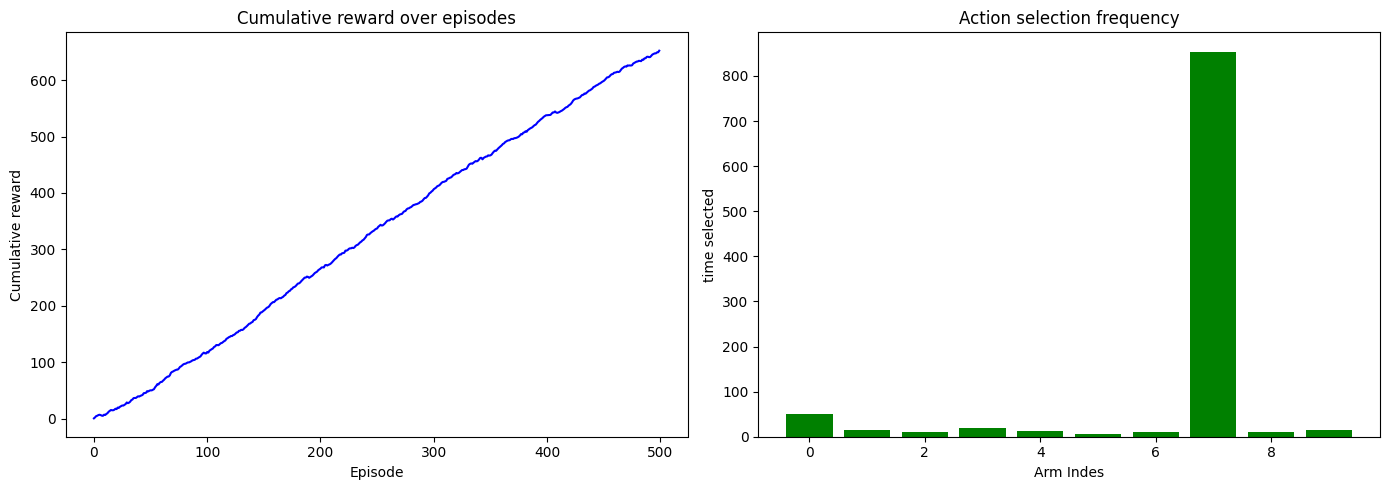

In [25]:
plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
plt.plot(np.cumsum(all_rewards),color='blue')
plt.title('Cumulative reward over episodes')
plt.xlabel('Episode')
plt.ylabel('Cumulative reward')
plt.subplot(1,2,2)
plt.bar(np.arange(n_arms), counts, color='green')
plt.title('Action selection frequency')
plt.xlabel('Arm Indes')
plt.ylabel('time selected')
plt.tight_layout()
plt.show()
